# Автоматическое обнаружение QRS-комплексов

## Цель

Разработать и оценить базовый алгоритм автоматического
обнаружения сердечных сокращений на одноканальной ЭКГ.

## Задачи

1. Загрузить подготовленную ЭКГ с частотой 250 Гц.
2. Выполнить полосовую фильтрацию.
3. Реализовать автоматический поиск R-пиков.
4. Сравнить найденные пики с экспертной разметкой MIT-BIH.
5. Рассчитать чувствительность и положительную
   прогностическую ценность детектора.

На данном этапе используется простой алгоритм поиска
локальных максимумов после фильтрации.

Экспертные аннотации не используются при обнаружении
пиков, а только для оценки результата.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from scipy.signal import (
    butter,
    sosfiltfilt,
    find_peaks
)

In [4]:
# Название записи
RECORD_NAME = "100"

# Текущая рабочая директория
current_dir = Path.cwd()

# Находим корень Git-репозитория
repo_root = next(
    (
        p for p in (current_dir, *current_dir.parents)
        if (p / ".git").exists()
    ),
    None
)

if repo_root is None:
    raise FileNotFoundError(
        "Не удалось найти корень Git-репозитория"
    )

# Папка с подготовленными данными
DATA_DIR = repo_root / "data" / "processed"

# Путь к файлу
file_path = DATA_DIR / f"mitdb_{RECORD_NAME}_250hz.npz"

# Загружаем файл
data = np.load(file_path, allow_pickle=False)

# Извлекаем массивы
ecg = data["ecg"].astype(np.float64)
fs = int(data["fs"].item())

reference_beats = data["beat_samples"]
reference_symbols = data["beat_symbols"]

print(f"Запись: {RECORD_NAME}")
print(f"Частота дискретизации: {fs} Гц")
print(f"Количество отсчётов: {len(ecg)}")
print(f"Продолжительность: {len(ecg) / fs:.2f} с")
print(f"Количество аннотаций: {len(reference_beats)}")

Запись: 100
Частота дискретизации: 250 Гц
Количество отсчётов: 451389
Продолжительность: 1805.56 с
Количество аннотаций: 2273


In [5]:
LOW_CUT = 5
HIGH_CUT = 20
FILTER_ORDER = 3

sos = butter(
    N=FILTER_ORDER,
    Wn=[LOW_CUT, HIGH_CUT],
    btype="bandpass",
    fs=fs,
    output="sos"
)

print("Форма массива коэффициентов:", sos.shape)
print(sos)

Форма массива коэффициентов: (3, 6)
[[ 0.00475052  0.00950105  0.00475052  1.         -1.6261983   0.6795993 ]
 [ 1.          0.         -1.          1.         -1.55335924  0.74863103]
 [ 1.         -2.          1.          1.         -1.9036069   0.9204806 ]]


In [6]:
filtered_ecg = sosfiltfilt(
    sos,
    ecg
)

print("Исходный массив:", ecg.shape)
print("Отфильтрованный:", filtered_ecg.shape)

Исходный массив: (451389,)
Отфильтрованный: (451389,)


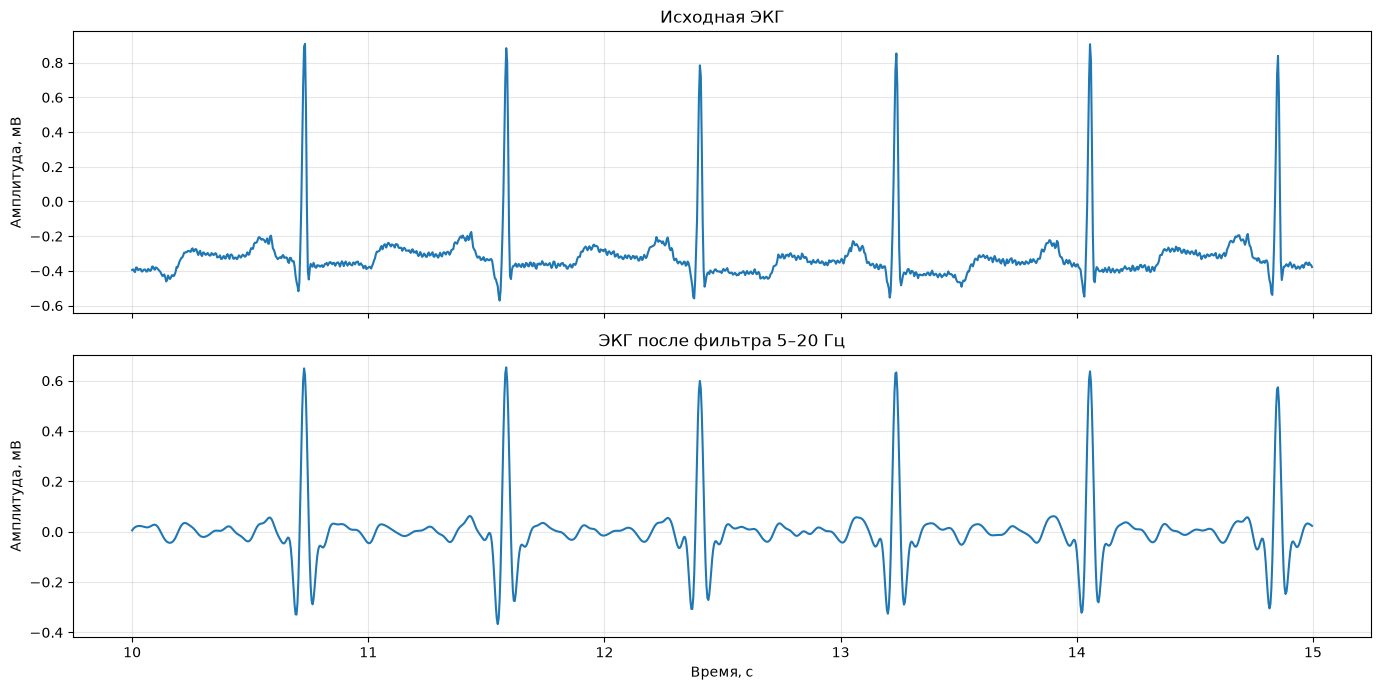

In [7]:
START_SEC = 10
DURATION_SEC = 5

start = int(START_SEC * fs)
end = int((START_SEC + DURATION_SEC) * fs)

time = np.arange(start, end) / fs

fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 7),
    sharex=True
)

axes[0].plot(
    time,
    ecg[start:end]
)

axes[0].set_title("Исходная ЭКГ")
axes[0].set_ylabel("Амплитуда, мВ")
axes[0].grid(alpha=0.3)

axes[1].plot(
    time,
    filtered_ecg[start:end]
)

axes[1].set_title("ЭКГ после фильтра 5–20 Гц")
axes[1].set_xlabel("Время, с")
axes[1].set_ylabel("Амплитуда, мВ")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [8]:
MIN_DISTANCE_SEC = 0.25
PROMINENCE_FACTOR = 1.5

min_distance_samples = max(
    1,
    int(round(MIN_DISTANCE_SEC * fs))
)

signal_std = np.std(filtered_ecg)

min_prominence = (
    PROMINENCE_FACTOR * signal_std
)

print("Минимальное расстояние:", min_distance_samples)
print("Стандартное отклонение:", signal_std)
print("Минимальная prominence:", min_prominence)

Минимальное расстояние: 62
Стандартное отклонение: 0.13604046724043367
Минимальная prominence: 0.2040607008606505


In [9]:
predicted_peaks, properties = find_peaks(
    filtered_ecg,
    distance=min_distance_samples,
    prominence=min_prominence
)

print("Обнаружено пиков:", len(predicted_peaks))
print("Референсных сокращений:", len(reference_beats))

Обнаружено пиков: 2275
Референсных сокращений: 2273


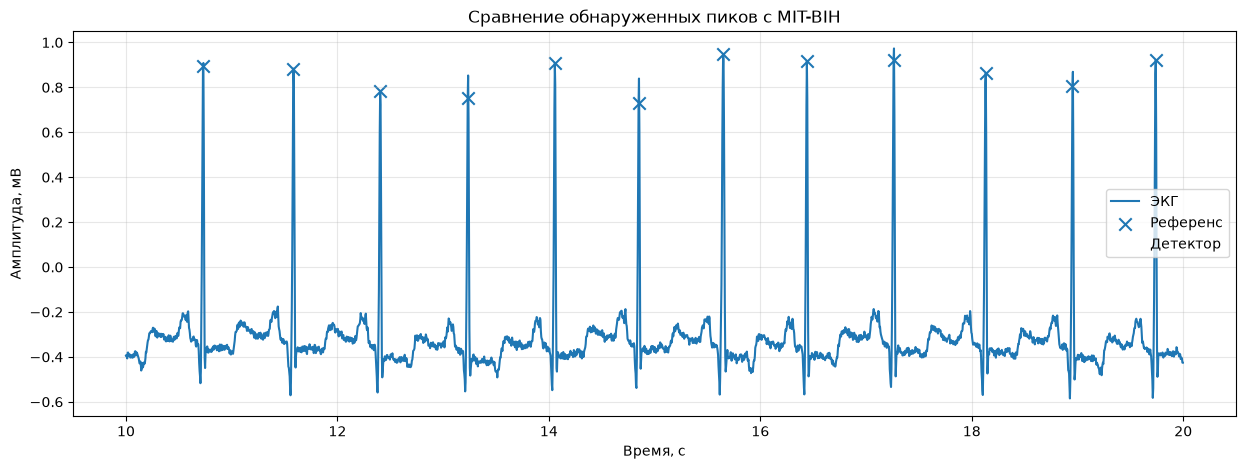

In [10]:
START_SEC = 10
DURATION_SEC = 10

start = int(START_SEC * fs)
end = int((START_SEC + DURATION_SEC) * fs)

time = np.arange(start, end) / fs

# Выбираем референсные аннотации внутри окна
ref_mask = (
    (reference_beats >= start)
    & (reference_beats < end)
)

ref_window = reference_beats[ref_mask]

# Выбираем обнаруженные пики внутри окна
pred_mask = (
    (predicted_peaks >= start)
    & (predicted_peaks < end)
)

pred_window = predicted_peaks[pred_mask]

# Строим график
plt.figure(figsize=(15, 5))

plt.plot(
    time,
    ecg[start:end],
    label="ЭКГ"
)

plt.scatter(
    ref_window / fs,
    ecg[ref_window],
    marker="x",
    s=80,
    label="Референс"
)

plt.scatter(
    pred_window / fs,
    ecg[pred_window],
    marker="o",
    facecolors="none",
    s=100,
    label="Детектор"
)

plt.xlabel("Время, с")
plt.ylabel("Амплитуда, мВ")
plt.title("Сравнение обнаруженных пиков с MIT-BIH")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [11]:
def evaluate_qrs_detector(
    reference,
    predicted,
    fs,
    tolerance_ms=100
):
    # Переводим допуск из мс в отсчёты
    tolerance_samples = int(
        round(tolerance_ms / 1000 * fs)
    )

    # Сортируем массивы
    reference = np.sort(np.asarray(reference))
    predicted = np.sort(np.asarray(predicted))

    # Индексы для прохода по двум массивам
    i = 0
    j = 0

    tp = 0
    timing_errors_ms = []

    while i < len(reference) and j < len(predicted):

        difference = predicted[j] - reference[i]

        if abs(difference) <= tolerance_samples:

            tp += 1

            timing_errors_ms.append(
                difference / fs * 1000
            )

            i += 1
            j += 1

        elif predicted[j] < reference[i]:

            j += 1

        else:

            i += 1

    fp = len(predicted) - tp
    fn = len(reference) - tp

    sensitivity = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    ppv = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else np.nan
    )

    return {
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Sensitivity": sensitivity,
        "PPV": ppv,
        "timing_errors_ms": np.asarray(timing_errors_ms)
    }

In [12]:
metrics = evaluate_qrs_detector(
    reference=reference_beats,
    predicted=predicted_peaks,
    fs=fs,
    tolerance_ms=100
)

print("TP:", metrics["TP"])
print("FP:", metrics["FP"])
print("FN:", metrics["FN"])

print(
    f"Sensitivity: {metrics['Sensitivity']:.4f}"
)

print(
    f"PPV: {metrics['PPV']:.4f}"
)

if len(metrics["timing_errors_ms"]) > 0:
    print(
        "Средняя абсолютная ошибка времени:",
        f"{np.mean(np.abs(metrics['timing_errors_ms'])):.2f} мс"
    )

TP: 2273
FP: 2
FN: 0
Sensitivity: 1.0000
PPV: 0.9991
Средняя абсолютная ошибка времени: 0.73 мс


In [13]:
RESULTS_DIR = repo_root / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Сохраняем найденные пики
np.save(
    RESULTS_DIR / "mitdb_100_baseline_peaks.npy",
    predicted_peaks
)

# Сохраняем основные метрики
metrics_df = pd.DataFrame([{
    "record": RECORD_NAME,
    "fs": fs,
    "tolerance_ms": 100,
    "TP": metrics["TP"],
    "FP": metrics["FP"],
    "FN": metrics["FN"],
    "Sensitivity": metrics["Sensitivity"],
    "PPV": metrics["PPV"]
}])

metrics_df.to_csv(
    RESULTS_DIR / "mitdb_100_baseline_metrics.csv",
    index=False
)

print("Результаты сохранены:", RESULTS_DIR)

Результаты сохранены: /workspaces/Design-of-microprocessor-based-medical-system/results


In [14]:
tolerance_ms = 100

tolerance_samples = int(
    round(tolerance_ms / 1000 * fs)
)

# Создаём маски сопоставленных событий
ref_matched = np.zeros(
    len(reference_beats),
    dtype=bool
)

pred_matched = np.zeros(
    len(predicted_peaks),
    dtype=bool
)

i = 0
j = 0

while (
    i < len(reference_beats)
    and j < len(predicted_peaks)
):
    difference = (
        predicted_peaks[j] - reference_beats[i]
    )

    if abs(difference) <= tolerance_samples:
        ref_matched[i] = True
        pred_matched[j] = True

        i += 1
        j += 1

    elif predicted_peaks[j] < reference_beats[i]:
        j += 1

    else:
        i += 1

false_positive_samples = predicted_peaks[~pred_matched]
false_negative_samples = reference_beats[~ref_matched]

print("Ложные обнаружения, с:")
print(false_positive_samples / fs)

print("\nПропущенные сокращения, с:")
print(false_negative_samples / fs)

Ложные обнаружения, с:
[ 996.128 1519.14 ]

Пропущенные сокращения, с:
[]


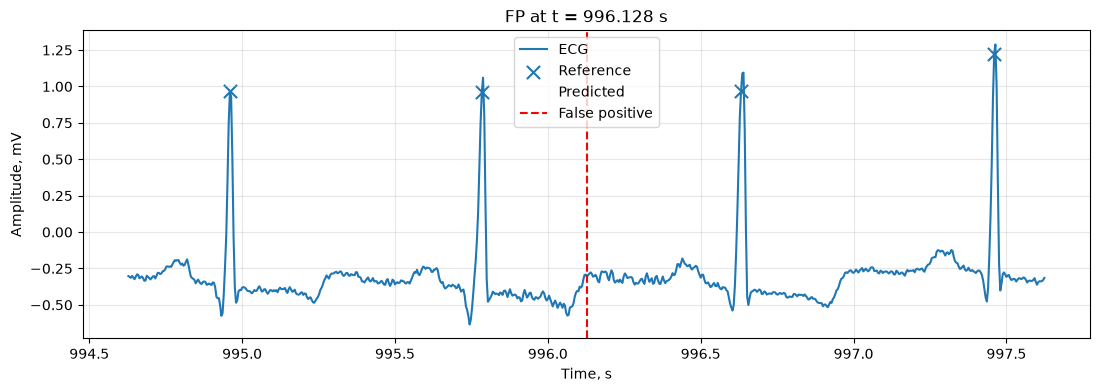

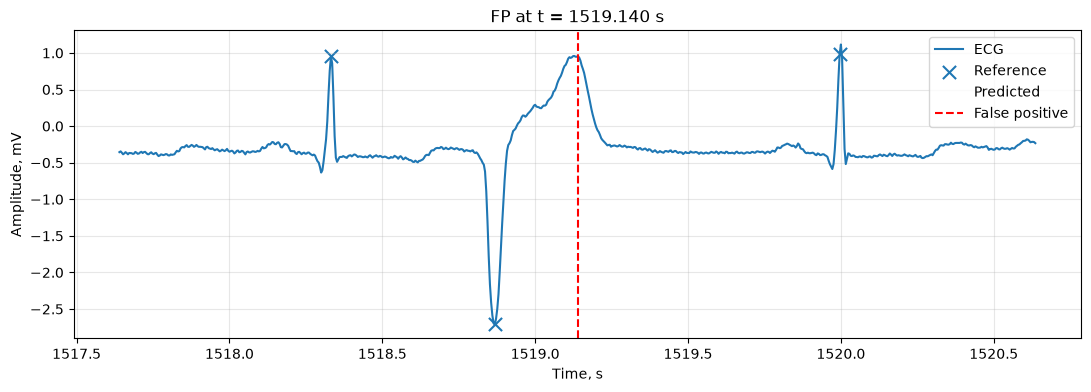

In [15]:
WINDOW_SEC = 1.5

for fp_sample in false_positive_samples:

    start = max(
        0,
        fp_sample - int(WINDOW_SEC * fs)
    )

    end = min(
        len(ecg),
        fp_sample + int(WINDOW_SEC * fs)
    )

    time = np.arange(start, end) / fs

    nearby_ref = reference_beats[
        (reference_beats >= start)
        & (reference_beats < end)
    ]

    nearby_pred = predicted_peaks[
        (predicted_peaks >= start)
        & (predicted_peaks < end)
    ]

    plt.figure(figsize=(13, 4))

    plt.plot(
        time,
        ecg[start:end],
        label="ECG"
    )

    plt.scatter(
        nearby_ref / fs,
        ecg[nearby_ref],
        marker="x",
        s=90,
        label="Reference"
    )

    plt.scatter(
        nearby_pred / fs,
        ecg[nearby_pred],
        marker="o",
        facecolors="none",
        s=90,
        label="Predicted"
    )

    plt.axvline(
        fp_sample / fs,
        color="red",
        linestyle="--",
        label="False positive"
    )

    plt.title(
        f"FP at t = {fp_sample / fs:.3f} s"
    )

    plt.xlabel("Time, s")
    plt.ylabel("Amplitude, mV")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

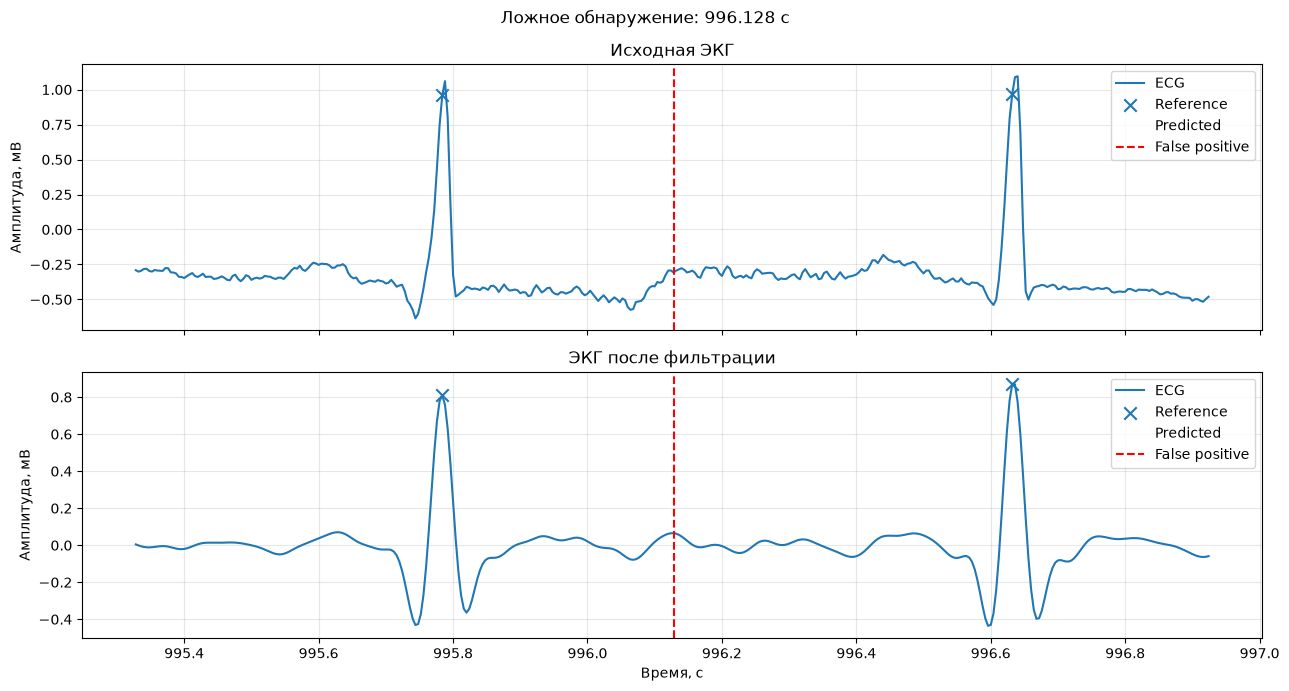

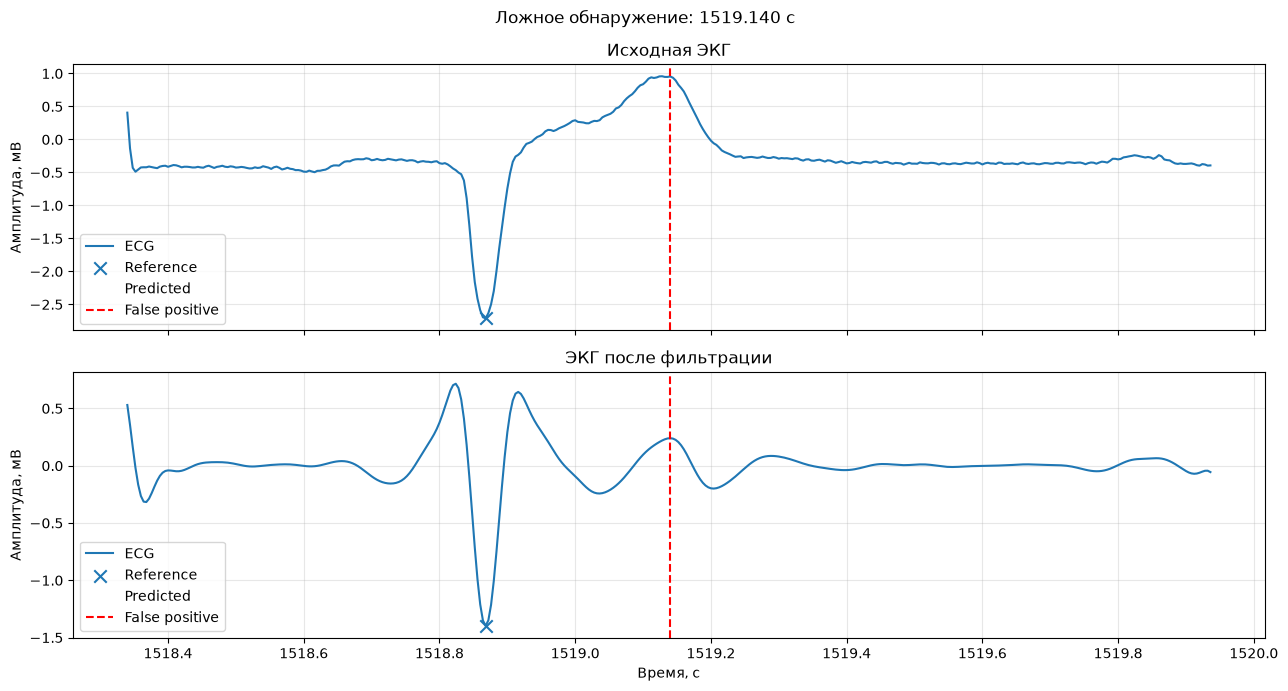

In [16]:
WINDOW_SEC = 0.8

for fp_sample in false_positive_samples:

    start = max(
        0,
        fp_sample - int(WINDOW_SEC * fs)
    )

    end = min(
        len(ecg),
        fp_sample + int(WINDOW_SEC * fs)
    )

    time = np.arange(start, end) / fs

    ref_window = reference_beats[
        (reference_beats >= start)
        & (reference_beats < end)
    ]

    pred_window = predicted_peaks[
        (predicted_peaks >= start)
        & (predicted_peaks < end)
    ]

    fig, axes = plt.subplots(
        2, 1,
        figsize=(13, 7),
        sharex=True
    )

    signals = [
        (ecg, "Исходная ЭКГ"),
        (filtered_ecg, "ЭКГ после фильтрации")
    ]

    for ax, (signal, title) in zip(axes, signals):

        ax.plot(
            time,
            signal[start:end],
            label="ECG"
        )

        ax.scatter(
            ref_window / fs,
            signal[ref_window],
            marker="x",
            s=80,
            label="Reference"
        )

        ax.scatter(
            pred_window / fs,
            signal[pred_window],
            marker="o",
            facecolors="none",
            s=80,
            label="Predicted"
        )

        ax.axvline(
            fp_sample / fs,
            color="red",
            linestyle="--",
            label="False positive"
        )

        ax.set_title(title)
        ax.set_ylabel("Амплитуда, мВ")
        ax.legend()
        ax.grid(alpha=0.3)

    axes[1].set_xlabel("Время, с")

    plt.suptitle(
        f"Ложное обнаружение: {fp_sample / fs:.3f} с"
    )

    plt.tight_layout()
    plt.show()

In [17]:
for fp_sample in false_positive_samples:

    # Находим место вставки FP среди референсных сокращений
    idx = np.searchsorted(
        reference_beats,
        fp_sample
    )

    # Предыдущее референсное сокращение
    prev_idx = idx - 1

    if prev_idx >= 0:

        prev_sample = reference_beats[prev_idx]
        prev_symbol = reference_symbols[prev_idx]

        delta_ms = (
            (fp_sample - prev_sample)
            / fs * 1000
        )

        print(f"FP: {fp_sample / fs:.3f} с")
        print(f"Предыдущее сокращение: {prev_symbol}")
        print(f"Время после него: {delta_ms:.1f} мс")
        print()

FP: 996.128 с
Предыдущее сокращение: N
Время после него: 344.0 мс

FP: 1519.140 с
Предыдущее сокращение: V
Время после него: 272.0 мс



In [18]:
v_mask = reference_symbols == "V"

v_samples = reference_beats[v_mask]

for v_sample in v_samples:

    # Ищем предсказания в пределах ±100 мс
    tolerance = int(round(0.1 * fs))

    nearby_peaks = predicted_peaks[
        np.abs(predicted_peaks - v_sample) <= tolerance
    ]

    print(f"Референс V: {v_sample / fs:.3f} с")
    print(f"Амплитуда ECG: {ecg[v_sample]:.3f} мВ")

    for peak in nearby_peaks:

        error_ms = (peak - v_sample) / fs * 1000

        print(f"\nНайденный пик: {peak / fs:.3f} с")
        print(f"Ошибка времени: {error_ms:.1f} мс")
        print(f"Исходная амплитуда: {ecg[peak]:.3f} мВ")
        print(
            f"Амплитуда после фильтрации: "
            f"{filtered_ecg[peak]:.3f} мВ"
        )

Референс V: 1518.868 с
Амплитуда ECG: -2.711 мВ

Найденный пик: 1518.824 с
Ошибка времени: -44.0 мс
Исходная амплитуда: -0.465 мВ
Амплитуда после фильтрации: 0.716 мВ


In [19]:
import wfdb

from scipy.signal import resample_poly
from fractions import Fraction

BEAT_SYMBOLS = {
    "N", "L", "R", "B",
    "A", "a", "J", "S",
    "V", "r", "F",
    "e", "j", "n", "E",
    "/", "f", "Q", "?"
}


def load_mitdb_record(record_name, target_fs=250):

    record = wfdb.rdrecord(
        record_name,
        pn_dir="mitdb",
        channels=[0]
    )

    annotations = wfdb.rdann(
        record_name,
        "atr",
        pn_dir="mitdb"
    )

    original_fs = int(record.fs)

    signal = record.p_signal[:, 0]

    # Выделяем только аннотации сокращений
    beat_mask = np.isin(
        annotations.symbol,
        list(BEAT_SYMBOLS)
    )

    beat_samples = annotations.sample[beat_mask]

    # Приводим сигнал к 250 Гц
    ratio = Fraction(target_fs, original_fs)

    signal_resampled = resample_poly(
        signal,
        ratio.numerator,
        ratio.denominator
    )

    # Пересчитываем координаты аннотаций
    beat_samples_resampled = np.rint(
        beat_samples / original_fs * target_fs
    ).astype(int)

    valid = (
        (beat_samples_resampled >= 0)
        & (beat_samples_resampled < len(signal_resampled))
    )

    return (
        signal_resampled,
        target_fs,
        beat_samples_resampled[valid]
    )

In [20]:
ecg_101, fs_101, ref_101 = load_mitdb_record("101")

# Те же параметры фильтра
sos_101 = butter(
    N=FILTER_ORDER,
    Wn=[LOW_CUT, HIGH_CUT],
    btype="bandpass",
    fs=fs_101,
    output="sos"
)

filtered_101 = sosfiltfilt(sos_101, ecg_101)

# Те же параметры поиска
predicted_101, _ = find_peaks(
    filtered_101,
    distance=int(round(MIN_DISTANCE_SEC * fs_101)),
    prominence=PROMINENCE_FACTOR * np.std(filtered_101)
)

# Та же функция оценки
metrics_101 = evaluate_qrs_detector(
    reference=ref_101,
    predicted=predicted_101,
    fs=fs_101,
    tolerance_ms=100
)

print("Record 101")
print("TP:", metrics_101["TP"])
print("FP:", metrics_101["FP"])
print("FN:", metrics_101["FN"])

print(f"Sensitivity: {metrics_101['Sensitivity']:.4f}")
print(f"PPV: {metrics_101['PPV']:.4f}")

Record 101
TP: 1865
FP: 6
FN: 0
Sensitivity: 1.0000
PPV: 0.9968
